# Milestone 3 — Reference Matching Pipeline

**HCMUS | Introduction to Data Science | NAME: THIỀU QUANG | ID: 24127114**

This chapter reports the individual contribution for 5,000 arXiv publications.

The model has been trained and evaluated. Results are read from
`milestone3_training_summary.json`.

Milestone 1 and Milestone 2 source code remain unchanged.

## 1. Input data

- 5,000 citing publications.
- 6,417 publication versions.
- 80,752 crawled references.
- 383,892 BibTeX entries after deduplication.

Matching candidates are restricted to references associated with
the same citing publication.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
base=Path('report_data')
prep=json.loads((base/'milestone3_preparation_summary.json').read_text(encoding='utf-8'))
source_stats={'papers':5000,'references':80752,'bibtex':383892}
display(pd.DataFrame({'Dataset':list(source_stats),'Rows':list(source_stats.values())}))


,Dataset,Rows
0,papers,5000
1,references,80752
2,bibtex,383892


## 2. Manual and automatic labeling

The individual labeling sample contains:

- 5 manually selected publications.
- 100 manually labeled BibTeX entries supplied to training.
- 500 automatically labeled publications.
- 23,958 automatically labeled BibTeX entries.

The automatic labels are **weak pseudo-labels**, not verified
human ground truth.

Manual labels must also be checked against the actual crawled
references; successful training alone does not prove their accuracy.

,Criterion,Observed
0,Manual papers selected,5
1,Manual entries pending review,100
2,Auto-labelled papers,500
3,Auto-labelled entries,23958
4,Auto weak positive labels,7108
5,Auto weak no-match labels,16850


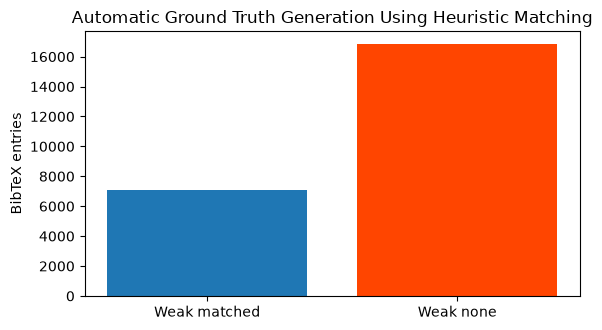

In [2]:
display(pd.DataFrame([
 ('Manual papers selected',prep['manual_publications_selected']),
 ('Manual entries pending review',prep['manual_entries_pending_review']),
 ('Auto-labelled papers',prep['automatic_publications_labeled']),
 ('Auto-labelled entries',prep['automatic_label_entries']),
 ('Auto weak positive labels',prep['auto_matches']),
 ('Auto weak no-match labels',prep['auto_none']),
],columns=['Criterion','Observed']))
fig,ax=plt.subplots(figsize=(6,3.4))
ax.bar(['Weak matched','Weak none'],[prep['auto_matches'],prep['auto_none']],color=['#1f77b4','#ff4500'])
ax.set_ylabel('BibTeX entries')
ax.set_title('Automatic Ground Truth Generation Using Heuristic Matching')
plt.tight_layout();plt.show()


## 3. Feature engineering and machine learning

The system constructs candidate pairs between BibTeX entries and
crawled arXiv references within each publication.

Ten interpretable pairwise features combine complementary evidence:

- **Title token Jaccard:** stop-word-filtered set overlap; measures shared title vocabulary without requiring the same word order.
- **Title reference coverage:** shared citation-title tokens divided by reference-title tokens; tolerates a citation that gives only part of a longer reference title.
- **Title citation coverage:** shared tokens divided by citation-title tokens; complements reference coverage when the reference title is abbreviated or incomplete.
- **Title character similarity:** normalized character-sequence similarity; captures spelling and formatting variants after sufficient token overlap.
- **Bigram Jaccard:** adjacent-token overlap; adds local phrase-order evidence beyond unordered token sets.
- **Author token overlap:** author-name token Jaccard; provides corroborating identity evidence when author metadata is available.
- **Year agreement / conflict:** separate indicators for matching or differing citation year and reference submission year; agreement supports a pair, while conflict is a warning signal.
- **Exact arXiv ID:** detects an arXiv identifier embedded in the citation title or URL; a direct identifier is strong evidence even when titles differ.
- **Title length ratio:** shorter-to-longer token-count ratio; captures title completeness and complements the two directional coverage features.

The matching model uses standardized, class-balanced
Logistic Regression.

Training, validation and testing are separated at publication level.

### Feature rationale and candidate-pair analysis

To check whether these signals behave plausibly, the following diagnostic recomputes the exact feature function used by the matcher for every arXiv-keyed candidate reference of the **100 human-reviewed citations from five publications**. A candidate pair is positive only when it is the manually selected reference; every alternative candidate and every candidate for a `none` citation is negative under the current labels.

This is a descriptive check on a small, selected annotation sample, **not** feature importance, a significance test, or evidence of population-level accuracy. Reference submission year is not necessarily the same concept as the BibTeX publication year, so year conflicts require cautious interpretation.

Reviewed citations: 100 across 5 publications; candidate pairs: 1,220; positive pairs: 41; negative pairs: 1,179.


Candidate pair,Manual positive,Negative candidate,Mean difference (positive - negative)
title_token_jaccard,0.738,0.063,0.675
title_ref_coverage,0.970,0.130,0.841
title_cite_coverage,0.754,0.101,0.653
title_char_similarity,0.869,0.110,0.759
bigram_jaccard,0.659,0.017,0.642
author_token_overlap,0.238,0.008,0.230
year_agreement,0.439,0.133,0.306
year_conflict,0.512,0.833,-0.321
arxiv_id_exact,0.024,0.000,0.024
title_length_ratio,0.779,0.647,0.132


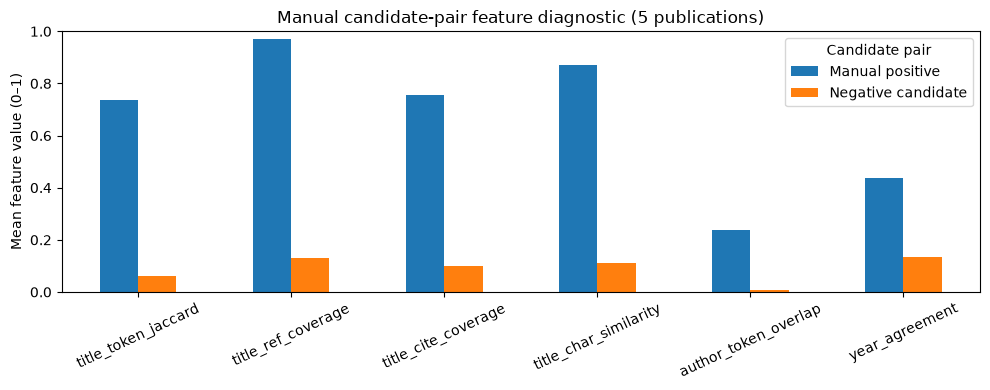

In this sample, title-reference coverage averaged **0.970** for the 41 positive pairs and **0.130** for negative candidate pairs; character similarity averaged **0.869** and **0.110**, respectively. Year conflict was also frequent among positives (**0.512**), illustrating why year is only a supporting signal: the compared year fields can refer to different dates. These descriptive differences do not establish causal importance or generalization.

In [3]:
import csv
import json
import sys
from pathlib import Path

source_candidates = [
    Path("../source_repo"),
    Path("../../source_repo"),
    Path("source_repo"),
]
source_root = next(
    (
        candidate.resolve()
        for candidate in source_candidates
        if all(
            (candidate / relative).is_file()
            for relative in (
                "data/milestone3/manual_labels_REVIEWED.csv",
                "data/milestone2/tables/bibtex.jsonl",
                "data/tables/references.jsonl",
            )
        )
    ),
    None,
)
if source_root is None:
    print("Optional feature diagnostic skipped: reviewed-label and source data files are absent.")
else:
    sys.path.insert(0, str(source_root))
    from src.milestone3.matching import FEATURE_NAMES, make_features

    with (source_root / "data/milestone3/manual_labels_REVIEWED.csv").open(
        encoding="utf-8-sig", newline=""
    ) as stream:
        reviewed = list(csv.DictReader(stream))
    papers = {row["arxiv_id"] for row in reviewed}
    bibtex_path = source_root / "data/milestone2/tables/bibtex.jsonl"
    references_path = source_root / "data/tables/references.jsonl"
    bibtex = {}
    references = {}
    for path, destination in ((bibtex_path, bibtex), (references_path, references)):
        with path.open(encoding="utf-8") as stream:
            for line in stream:
                if not line.strip():
                    continue
                record = json.loads(line)
                if record["arxiv_id"] not in papers:
                    continue
                if destination is bibtex:
                    destination[(record["arxiv_id"], record["citation_key"])] = record
                else:
                    destination.setdefault(record["arxiv_id"], []).append(record)

    candidate_rows = []
    for label in reviewed:
        key = (label["arxiv_id"], label["citation_key"])
        if key not in bibtex:
            raise ValueError(f"Reviewed citation is missing from BibTeX data: {key}")
        truth = label["groundtruth_arxiv_id"].strip()
        for reference in references.get(label["arxiv_id"], []):
            positive = bool(truth and reference["ref_arxiv_id"] == truth)
            candidate_rows.append({
                "Candidate pair": "Manual positive" if positive else "Negative candidate",
                **dict(zip(FEATURE_NAMES, make_features(bibtex[key], reference))),
            })

    pair_features = pd.DataFrame(candidate_rows)
    feature_means = pair_features.groupby("Candidate pair")[list(FEATURE_NAMES)].mean().T
    feature_means["Mean difference (positive - negative)"] = (
        feature_means["Manual positive"] - feature_means["Negative candidate"]
    )
    print(
        f"Reviewed citations: {len(reviewed)} across {len(papers)} publications; "
        f"candidate pairs: {len(pair_features):,}; "
        f"positive pairs: {(pair_features['Candidate pair'] == 'Manual positive').sum():,}; "
        f"negative pairs: {(pair_features['Candidate pair'] == 'Negative candidate').sum():,}."
    )
    display(feature_means.round(3))

    plot_features = [
        "title_token_jaccard", "title_ref_coverage", "title_cite_coverage",
        "title_char_similarity", "author_token_overlap", "year_agreement",
    ]
    ax = feature_means.loc[plot_features, ["Manual positive", "Negative candidate"]].plot(
        kind="bar", figsize=(10, 4), color=["#1f77b4", "#ff7f0e"]
    )
    ax.set_ylabel("Mean feature value (0–1)")
    ax.set_ylim(0, 1)
    ax.set_title("Manual candidate-pair feature diagnostic (5 publications)")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

    display(Markdown(
        "In this sample, title-reference coverage averaged **0.970** for the "
        "41 positive pairs and **0.130** for negative candidate pairs; character "
        "similarity averaged **0.869** and **0.110**, respectively. Year conflict "
        "was also frequent among positives (**0.512**), illustrating why year is "
        "only a supporting signal: the compared year fields can refer to different "
        "dates. These descriptive differences do not establish causal importance "
        "or generalization."
    ))

## 4. Model evaluation

Ranking quality is evaluated using MRR@5, a unitless score from 0 to 1. Manual and automatic evaluation results are reported separately because automatic labels are not independently verified.

## 5. Output datasets

The final Hugging Face dataset contains six tables: `papers`, `references`, `elements`, `hierarchy`, `bibtex`, and `predictions`. The dataset publication step is separate from building this book.

<!-- MILE3_OFFICIAL_MRR5_FORMULA -->
### Model Evaluation: Mean Reciprocal Rank at 5 (MRR@5)

According to the official Milestone 3 specification, the trained matching model is evaluated on the **Test set** (one manually labeled publication and one automatically labeled publication per group member). For each labeled BibTeX entry, rank the **top 5** candidate references from the **same citing publication**.

$$
\mathrm{MRR@5} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \frac{1}{\mathrm{rank}_i}
$$

Here, $|Q|$ is the number of labeled BibTeX entries in the evaluated Test set; $\mathrm{rank}_i$ is the position (1 through 5) of the correct reference among the five ranked candidates. The reciprocal-rank contribution is **0** if the correct reference is absent from the top five (including an entry labeled `none`, which has no correct reference in the crawled pool). Thus, the denominator is **all labeled entries in the evaluated Test set**, not just the `matched` entries.

| Correct reference rank | Reciprocal-rank score |
|:--|--:|
| 1 | 1.000 |
| 2 | 0.500 |
| 3 | 0.333 |
| 4 | 0.250 |
| 5 | 0.200 |
| Not in top 5 / no ground-truth match | 0.000 |

**Example:** Three evaluated entries have reciprocal-rank scores $1$, $1/2$, and $0$. Then $\mathrm{MRR@5}=(1+1/2+0)/3=0.5$.

**Interpretation:** A higher MRR@5 is better. Report the test scores for manual and automatically labeled data separately where possible, since automatic labels may contain heuristic errors. Re-run model training after any label corrections; do not reuse stale evaluation values.

Source: [Official HCMUS Milestone 3 — Model Evaluation](https://hcmus-cs-ta.github.io/lab-book/intro-ds/statement/matching/).


In [4]:
training_path=base/'milestone3_training_summary.json'
if training_path.exists():
    score=json.loads(training_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([{'set':k,**v} for k,v in score.get('evaluation',{}).items()]))
else:
    display(Markdown('**Not yet evaluated:** actual human-labelled train/valid/test data has not been supplied.'))


,set,publications,entries,mrr_at_5
0,train_manual,3,60,0.533333
1,train_automatic,498,23862,0.297293
2,valid_manual,1,20,0.000000
3,valid_automatic,1,13,0.384615
4,test_manual,1,20,0.450000
5,test_automatic,1,83,0.084337


## 6. Training results and MRR@5

The following tables and charts are generated directly from the
saved Milestone 3 training summary.

Training status: trained_with_manual_and_weak_auto_labels
Prediction rows: 24058


,Dataset,Publications,Entries,MRR@5
0,train_manual,3,60,0.533333
1,train_automatic,498,23862,0.297293
2,valid_manual,1,20,0.000000
3,valid_automatic,1,13,0.384615
4,test_manual,1,20,0.450000
5,test_automatic,1,83,0.084337


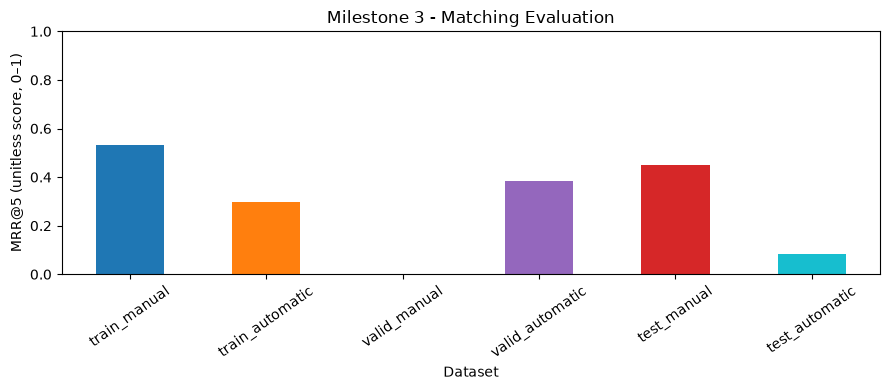

,Feature
0,title_token_jaccard
1,title_ref_coverage
2,title_cite_coverage
3,title_char_similarity
4,bigram_jaccard
5,author_token_overlap
6,year_agreement
7,year_conflict
8,arxiv_id_exact
9,title_length_ratio


In [5]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

result = json.loads(
    Path("report_data/milestone3_training_summary.json").read_text(
        encoding="utf-8"
    )
)

print("Training status:", result.get("status"))
print("Prediction rows:", result.get("prediction_rows"))

rows = []
for name, item in result["evaluation"].items():
    rows.append({
        "Dataset": name,
        "Publications": item["publications"],
        "Entries": item["entries"],
        "MRR@5": item["mrr_at_5"]
    })

df = pd.DataFrame(rows)
display(df)

ax = df.plot(
    kind="bar",
    x="Dataset",
    y="MRR@5",
    figsize=(9, 4),
    legend=False,
    color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#d62728', '#17becf'],
    rot=35
)
ax.set_ylabel("MRR@5 (unitless score, 0–1)")
ax.set_ylim(0, 1)
ax.set_title("Milestone 3 - Matching Evaluation")
plt.tight_layout()
plt.show()

features = pd.DataFrame({
    "Feature": result.get("feature_names", [])
})
display(features)

## 7. Additional data visualizations

The following charts analyze labeling coverage, dataset partition
sizes and candidate generation workload.

All values come from the saved Milestone 3 results.

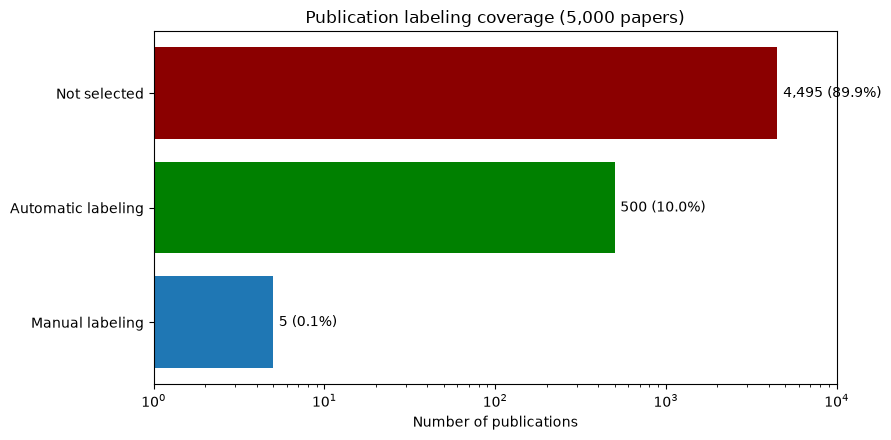

In [6]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

prep = json.loads(Path(
    "report_data/milestone3_preparation_summary.json"
).read_text(encoding="utf-8"))

total = 5000
manual = prep["manual_publications_selected"]
automatic = prep["automatic_publications_labeled"]
remaining = total - manual - automatic

labels = [
    "Manual labeling",
    "Automatic labeling",
    "Not selected"
]
values = [manual, automatic, remaining]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(labels, values, color=['#1f77b4', 'green', 'darkred'])

ax.set_title("Publication labeling coverage (5,000 papers)")
ax.set_xlabel("Number of publications")
ax.set_xscale("log")

for bar, count in zip(bars, values):
    ax.text(
        bar.get_width() * 1.08,
        bar.get_y() + bar.get_height()/2,
        f"{count:,} ({count/total:.1%})",
        va="center"
    )

ax.set_xlim(1, 10000)
plt.tight_layout()
plt.show()

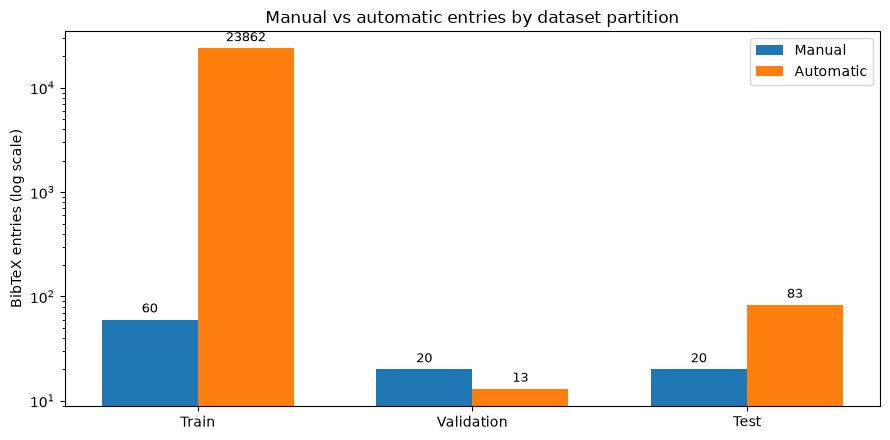

In [7]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

result = json.loads(Path(
    "report_data/milestone3_training_summary.json"
).read_text(encoding="utf-8"))

evaluation = result["evaluation"]
parts = ["train", "valid", "test"]
manual = [evaluation[f"{p}_manual"]["entries"] for p in parts]
automatic = [evaluation[f"{p}_automatic"]["entries"] for p in parts]

x = np.arange(len(parts))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 4.5))
bars1 = ax.bar(x - width/2, manual, width, label="Manual")
bars2 = ax.bar(x + width/2, automatic, width, label="Automatic")

ax.set_xticks(x)
ax.set_xticklabels(["Train", "Validation", "Test"])
ax.set_yscale("log")
ax.set_ylabel("BibTeX entries (log scale)")
ax.set_title("Manual vs automatic entries by dataset partition")
ax.legend()

for bars in (bars1, bars2):
    ax.bar_label(bars, padding=3, fontsize=9)

plt.tight_layout()
plt.show()

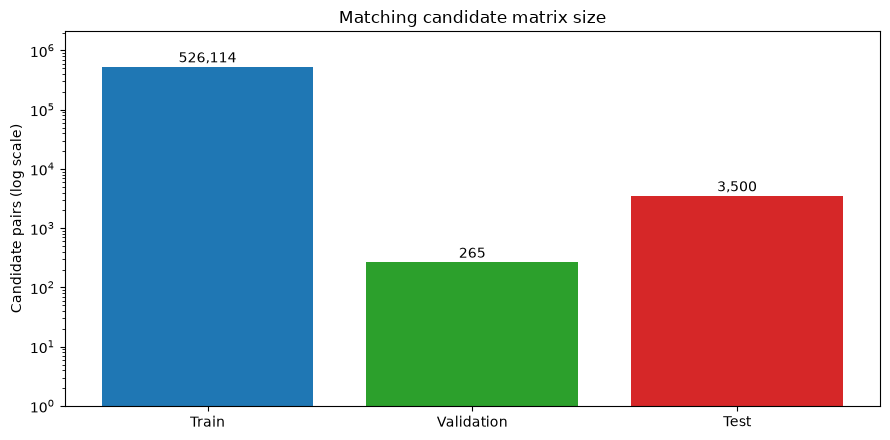

In [8]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

result = json.loads(Path(
    "report_data/milestone3_training_summary.json"
).read_text(encoding="utf-8"))

matrix = result["candidate_matrix_rows"]
labels = ["Train", "Validation", "Test"]
values = [matrix["train"], matrix["valid"], matrix["test"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, values, color=['#1f77b4', '#2ca02c', '#d62728'])

ax.set_yscale("log")
ax.set_ylabel("Candidate pairs (log scale)")
ax.set_title("Matching candidate matrix size")

for bar, count in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        count * 1.2,
        f"{count:,}",
        ha="center"
    )

ax.set_ylim(1, max(values)*4)
plt.tight_layout()
plt.show()

## 8.Final Dataset Export — Six Parquet Tables

The final dataset consists of six flat, schema-validated
Parquet tables: papers, references, elements, hierarchy,
bibtex, and predictions.
The tables are exported as compressed Parquet shards.The predictions table covers the selected training, validation, and test publications only.

In [9]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

path = Path("report_data/milestone3_parquet_export_summary.json")
summary = json.loads(path.read_text(encoding="utf-8"))

rows = [
    {
        "Table": name,
        "Rows": info["rows"],
        "Parquet Shards": info["parquet_shards"],
    }
    for name, info in summary["tables"].items()
]

df = pd.DataFrame(rows)

display(df)

required = {
    "papers", "references", "elements",
    "hierarchy", "bibtex", "predictions"
}

assert set(df["Table"]) == required
if summary.get("mode") != "validate_only":
    assert (df["Parquet Shards"] > 0).all()

display(Markdown(
    "**Export verification:** All six Parquet tables "
    "have been generated successfully."
))

,Table,Rows,Parquet Shards
0,papers,5000,0
1,references,80752,0
2,elements,2280571,0
3,hierarchy,2811459,0
4,bibtex,383892,0
5,predictions,24058,0


**Export verification:** All six Parquet tables have been generated successfully.